# Titanic Data Analysis

## Internship Final Project

This project analyzes the Titanic dataset to understand passenger survival patterns using Python, Pandas, Matplotlib, and Seaborn.


In [26]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [27]:
df= pd.read_csv("Titanic-Dataset.csv")

In [28]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [29]:
print("Shape:" , df.shape)

Shape: (891, 12)


In [30]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [31]:
print(df[["Age" , "Embarked" , "Cabin"]].isnull().sum())

Age         177
Embarked      2
Cabin       687
dtype: int64


In [32]:
df=df.drop(columns=["Cabin"])

In [33]:
df["Age"] = df["Age"].fillna(df["Age"].median())

In [34]:
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

In [35]:
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

In [36]:
df.duplicated().sum()

np.int64(0)

In [37]:
print(df["Survived"].value_counts())

Survived
0    549
1    342
Name: count, dtype: int64


In [38]:
survival_rate = df["Survived"].mean()*100
print("Overall Survival Rate:", survival_rate, "%")

Overall Survival Rate: 38.38383838383838 %


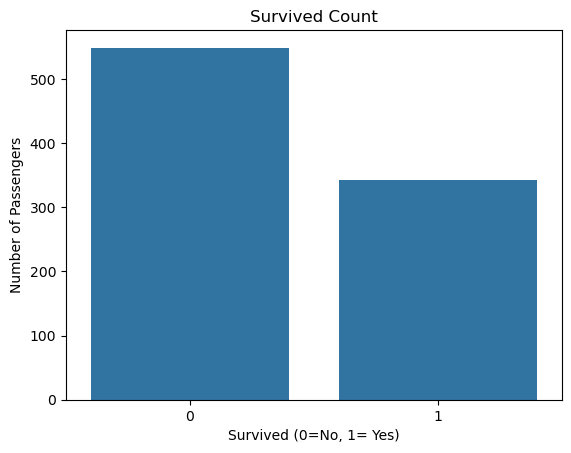

In [39]:
sns.countplot(data=df , x="Survived")


plt.title("Survived Count")
plt.xlabel("Survived (0=No, 1= Yes)")
plt.ylabel("Number of Passengers")

plt.show()


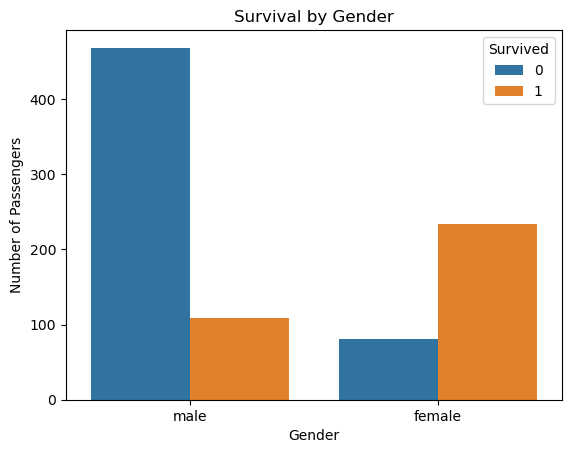

In [40]:
sns.countplot(data=df, x="Sex", hue="Survived")

plt.title("Survival by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.show()


In [41]:
gender_survival = df.groupby("Sex")["Survived"].mean() * 100

print(gender_survival)


Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64


In [42]:
print(df.groupby("Pclass")["Survived"].mean() * 100)


Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


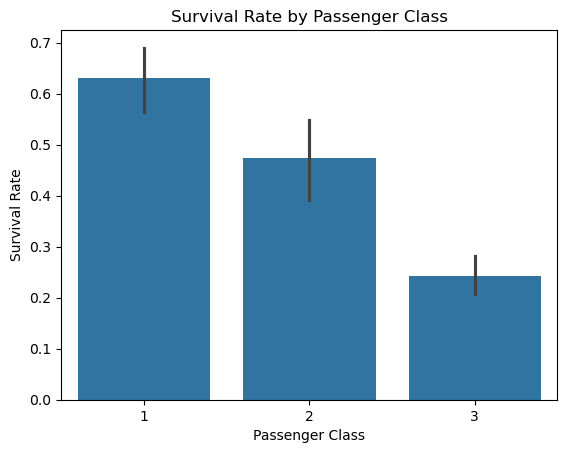

In [43]:
sns.barplot(data=df, x="Pclass", y="Survived")

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")

plt.show()


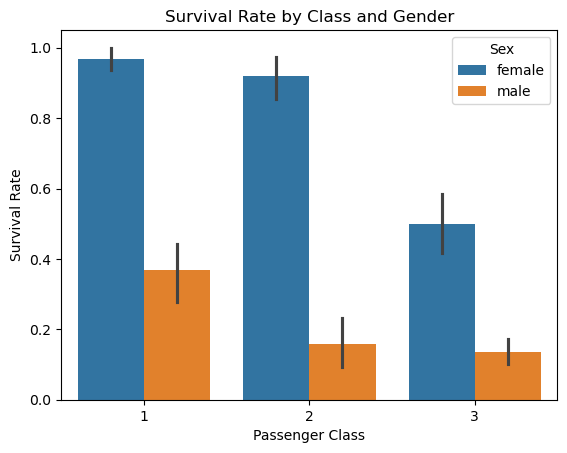

In [44]:
sns.barplot(data=df, x="Pclass", y="Survived", hue="Sex")

plt.title("Survival Rate by Class and Gender")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")

plt.show()


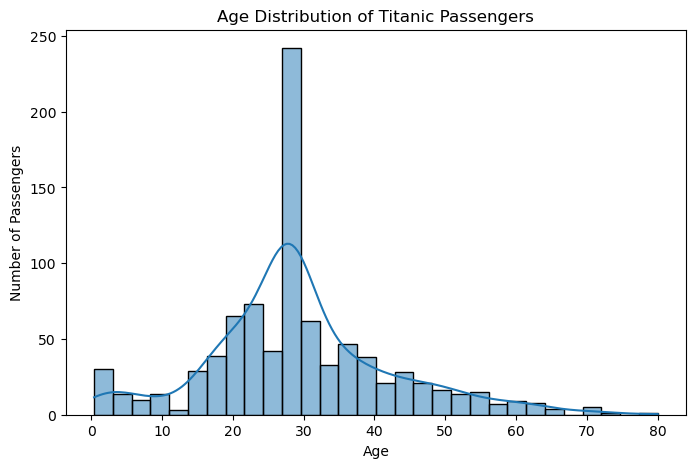

In [45]:
plt.figure(figsize=(8,5))

sns.histplot(data=df, x="Age", bins=30, kde=True)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()


In [46]:
df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teenager", "Young Adult", "Adult", "Senior"]
)

print(df.groupby("Age_Group", observed=True)["Survived"].mean() * 100)


Age_Group
Child          57.971014
Teenager       42.857143
Young Adult    35.327103
Adult          40.000000
Senior         22.727273
Name: Survived, dtype: float64


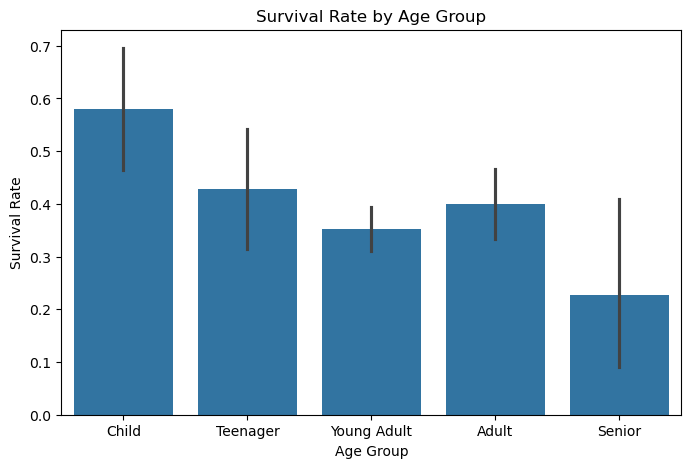

In [47]:
plt.figure(figsize=(8,5))

sns.barplot(data=df, x="Age_Group", y="Survived")

plt.title("Survival Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate")

plt.show()


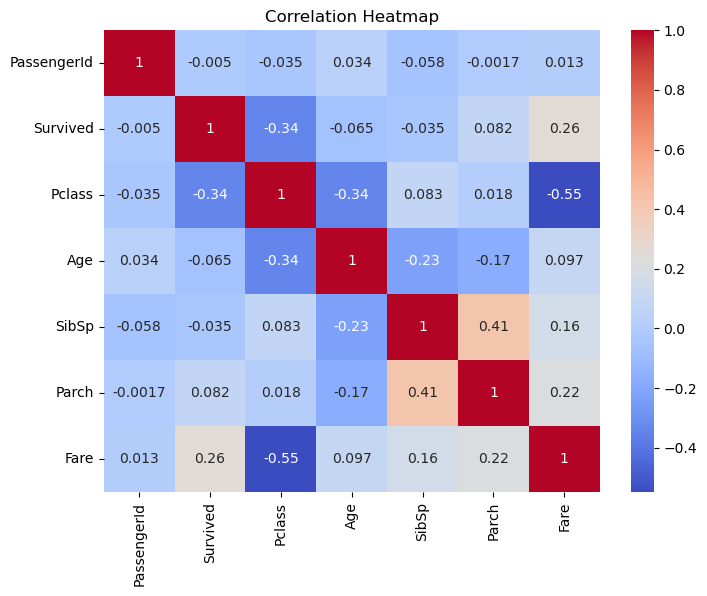

In [48]:
plt.figure(figsize=(8,6))

numeric_cols = df.select_dtypes(include="number")

sns.heatmap(
    numeric_cols.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()


In [49]:
print("Overall Survival Rate:")
print(df["Survived"].mean() * 100)

print("\nSurvival by Gender:")
print(df.groupby("Sex")["Survived"].mean() * 100)

print("\nSurvival by Class:")
print(df.groupby("Pclass")["Survived"].mean() * 100)

print("\nSurvival by Age Group:")
print(df.groupby("Age_Group", observed=True)["Survived"].mean() * 100)


Overall Survival Rate:
38.38383838383838

Survival by Gender:
Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64

Survival by Class:
Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64

Survival by Age Group:
Age_Group
Child          57.971014
Teenager       42.857143
Young Adult    35.327103
Adult          40.000000
Senior         22.727273
Name: Survived, dtype: float64


In [50]:
print("Overall Survival Rate:")
print(df["Survived"].mean() * 100)

print("\nSurvival by Gender:")
print(df.groupby("Sex")["Survived"].mean() * 100)

print("\nSurvival by Class:")
print(df.groupby("Pclass")["Survived"].mean() * 100)


Overall Survival Rate:
38.38383838383838

Survival by Gender:
Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64

Survival by Class:
Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64
